# Schematic for multiscale alkylated polythiophenes
Inspired in part by https://doi.org/10.1021/acs.macromol.4c00232

In [1]:
import numpy as np
from networkx import spring_layout, kamada_kawai_layout

from mupt.mupr.primitives import (
    Primitive,
    RootPrimitive,
    CompositePrimitive,
    SimplePrimitive,
    AtomicPrimitive,
)
from mupt.mupr.properties import is_atom, is_superatomic, is_subdominant

from mupt.graphs.generators import path_graph_from_sequence
from mupt.interfaces.smiles import primitive_from_smiles
from mupt.interfaces.mosdef.mbuild import primitive_to_mbuild

In [2]:
from enum import Enum

class AlkylTailLength(Enum):
    """Easy-to-read specification of number of carbons in thiophene tail"""
    NONE = 0
    PROPYL = 3
    HEXYL = 6
    NONYL = 9
    DODECYL = 12
    
    def prefix(self) -> str:
        if self is AlkylTailLength.NONE:
            return ""
        return f"3-{self.name.lower()}"
        
    def num_propyls(self) -> int:
        return self.value // 3

# Assemble single P3[n]T chain

In [3]:
## choose these as you please

# tail_len : AlkylTailLength = AlkylTailLength.NONE
tail_len : AlkylTailLength = AlkylTailLength.HEXYL

## Assemble tail fragments

In [4]:
lexicon_tail : dict[str, Primitive] = {
    "propyl" : primitive_from_smiles(
        "[*:3]-[CH2:4]-[CH2]-[CH2:3]-[*:4]",
        label="propyl",
    ),
    "H" : primitive_from_smiles(
        "[*:3]-[H:4]",
        label="H cap tail",
    ),
}

<Axes: >

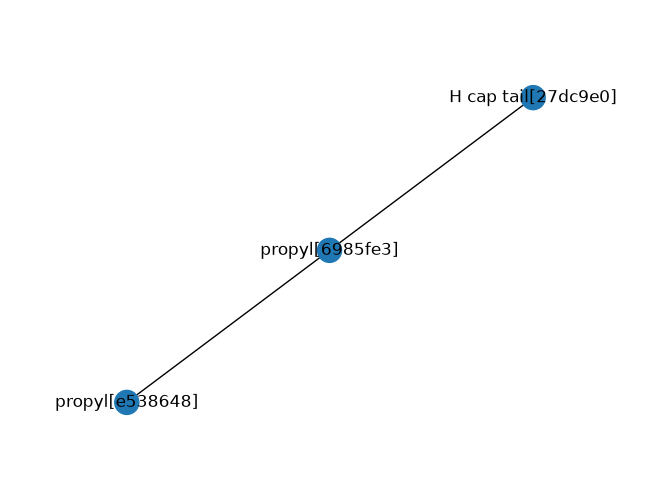

In [5]:
# H must come first to set connector orientation for linker
sequence : list[str] = ["H"] + ["propyl"]*tail_len.num_propyls()

tail = CompositePrimitive(label="tail")
tail.populate_from_topology_and_lexicon(
    topology=path_graph_from_sequence(sequence),
    lexicon=lexicon_tail,
)

tail.visualize_cross_section(is_subdominant)

## Assemble backbone repeat unit

### Middle repeat unit

In [6]:
thiophene_backbone = primitive_from_smiles(
    # using 6 to mark ring closure to disambiguate
    "[*:1]-[c:2]6:[cH]:[c:3](-[*:4]):[c:1](:s:6)-[*:2]",
    label="thiophene core"
)

thiophene_mid = CompositePrimitive(
    children=[thiophene_backbone, tail],
    label="thiophene",
)
thiophene_backbone.connect_neighbor(tail)
print(thiophene_mid.hierarchy_summary(to_depth=4))

thiophene
├── thiophene core
│   ├── C-1
│   ├── C-2
│   ├── C-3
│   ├── C-5
│   ├── S-6
│   ╰── H-8
╰── tail
    ├── H cap tail
    │   ╰── H-1
    ├── propyl
    │   ├── C-1
    │   ├── C-2
    │   ├── C-3
    │   ├── H-5
    │   ├── H-6
    │   ├── H-7
    │   ├── H-8
    │   ├── H-9
    │   ╰── H-10
    ╰── propyl
        ├── C-1
        ├── C-2
        ├── C-3
        ├── H-5
        ├── H-6
        ├── H-7
        ├── H-8
        ├── H-9
        ╰── H-10


### Head repeat unit

In [7]:
H_cap = primitive_from_smiles("[H:1]-[*:2]", label="H cap backbone")
new_thiophene_0 = thiophene_mid.copy() # ensure distinct from core prototype

thiophene_head = CompositePrimitive(
    children=[new_thiophene_0, H_cap],
    label="thiophene_head",
)
new_thiophene_0.connect_neighbor(H_cap)

### Tail repeat unit

In [8]:
vinyl_cap =  primitive_from_smiles("[*:1]-[C:2]=C", label="vinyl")
new_thiophene_1 = thiophene_mid.copy() # ensure distinct from core prototype

thiophene_tail = CompositePrimitive(
    children=[new_thiophene_1, vinyl_cap],
    label="thiophene_tail",
)
new_thiophene_1.connect_neighbor(vinyl_cap)

## Assemble single linear chain

In [9]:
lexicon : dict[str, Primitive] = {
    "head" : thiophene_head,
    "mid"  : thiophene_mid,
    "tail" : thiophene_tail,
}

monomer_name : str = f"{tail_len.prefix()}thiophene"
polymer_name : str = f"poly({monomer_name})"

In [10]:
def polythiophene_chain(DOP: int) -> CompositePrimitive:
    """
    Assemble a single multiscale alkylated polythiophene 
    chain with the desired number of repeat units
    """
    sequence = ['head'] + (DOP - 2)*['mid'] + ['tail']
    sequence_graph = path_graph_from_sequence(sequence)
    molecule = CompositePrimitive(label=polymer_name)
    molecule.populate_from_topology_and_lexicon(
        sequence_graph,
        lexicon=lexicon,
    )
    
    return molecule

# Examining at various resolution scales
Can choose level of coarse graining (including none at all) at whim,  
even for a very ragged hierarchy such as the one we've just assembled

In [11]:
chain = polythiophene_chain(15)

### 1 bead per residue CG

<Axes: >

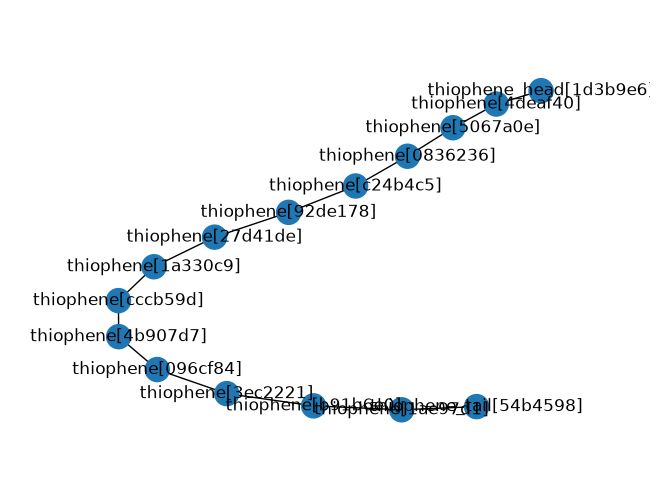

In [12]:
chain.visualize_cross_section(is_subdominant)

### Many bead per residue (3 carbon tail beads)

<Axes: >

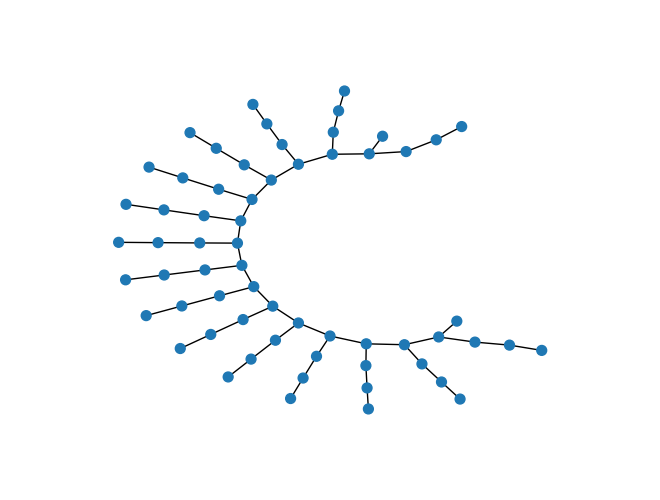

In [13]:
# NOTE: not quite right; need to select res w/ cap atoms lumped together
xsec_tail_beads = chain.cross_section(is_superatomic)
pos = kamada_kawai_layout(xsec_tail_beads, dim=2)
chain.visualize_cross_section(xsec_tail_beads, pos=pos, with_labels=False, node_size=50)

### All-atom

In [14]:
xsec_aa = chain.cross_section(is_atom)

<Axes: >

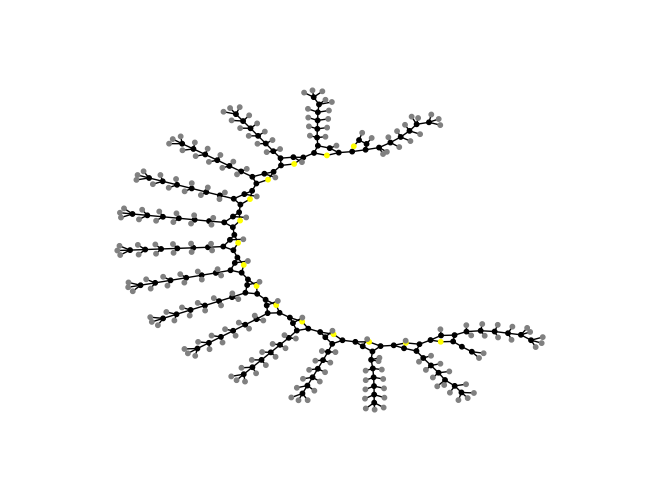

In [15]:
pos = kamada_kawai_layout(xsec_aa, dim=2) # takes a sec - equivalent to running small FF for coords
chain.visualize_cross_section(xsec_aa, pos=pos, with_labels=False, node_size=10)

## Export to mBuild

In [16]:
num_chains : int = 5
DOP_min : int = 5
DOP_max : int = 15

In [17]:
chain_lens = np.random.randint(DOP_min, DOP_max, size=num_chains)

system = RootPrimitive(
    box_vectors=10.0*np.eye(3, dtype=float),
    children=[polythiophene_chain(chain_len) for chain_len in chain_lens]
)

In [18]:
# change predicate to export different slices of repr
compound = primitive_to_mbuild(system, predicate=is_atom)
display(compound)
# TODO: integrate w/ Path to generate interesting coordinates

<ROOT 1450 particles, 1502 bonds, non-periodic, id: 131170472762432>

In [19]:
import networkx as nx

len(list(nx.connected_components(compound.bond_graph)))

5

<Axes: >

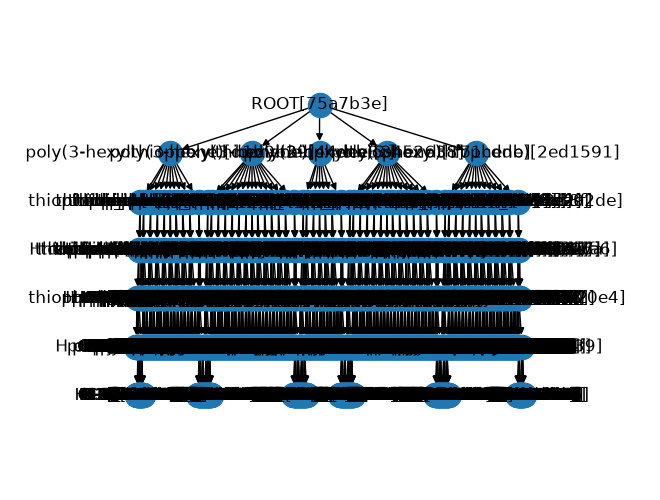

In [20]:
system.visualize_hierarchy()

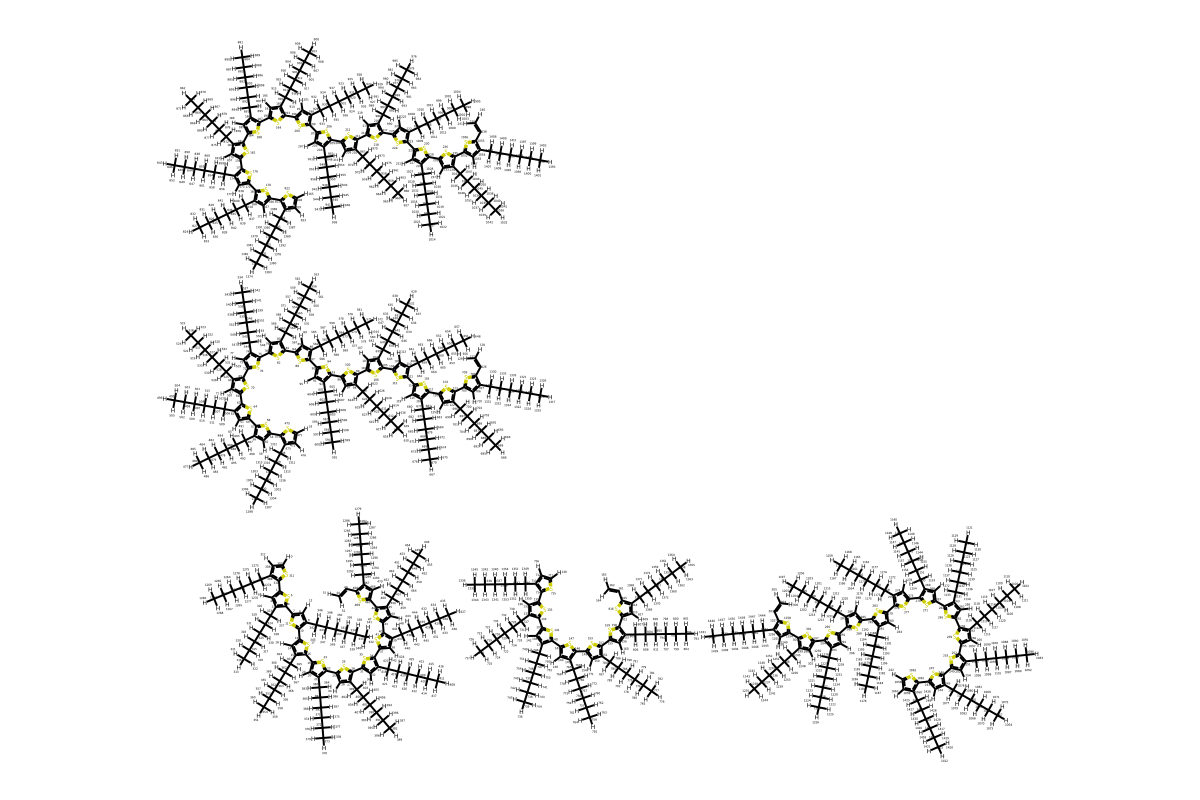

In [21]:
from mupt.chemistry.rdkit.depiction import set_rdkdraw_size

set_rdkdraw_size(800, 3/2)

mols = compound.to_rdkit()
for atom in mols.GetAtoms():
    atom.ClearProp('atomLabel')
display(mols)